# BALLADEER — 03. Preprocesamiento (pasos 2.1–2.10 y 3.1)

Plan experimental v05 (`experiments-plan-experimental-mil-creda-sobre-balladeer-v05.md`), secciones 2.1–2.10 y 3.1.

**Este cuaderno es el punto de entrada reproducible del preprocesamiento.** Ejecutado de arriba abajo sobre un clon limpio del repositorio, con solo los datos crudos en `MIL-CREDA/Data/raw/`, toma el release crudo y produce `MIL-CREDA/Data/processed/` completo: un archivo por registro, el manifiesto, las tablas de flujo y los cruces. Después muestra las estadísticas y las figuras. No lee ninguna salida de la auditoría ni ningún archivo fuera del control de versiones, salvo los datos crudos: cada exclusión y cada marca se recalcula desde el crudo con las funciones del paquete.

| Paso | Módulo | Qué hace |
|---|---|---|
| todo el flujo | `preprocess` | verifica el crudo, borra el caché si `REBUILD`, corre el pipeline y escribe las salidas |
| 2.1, 2.7 | `preprocess_filter` | solo canales de cuero cabelludo (29 CGX, 14 Emotiv), banda 0,2–45 Hz sobre la grabación continua y **después** remuestreo a 128 Hz |
| 3.1, 2.3–2.5, 2.8 | `windows` | ventanas de 4 s sin solape (512 muestras), sin la primera ni la parcial final; marcas por ventana como datos laterales |
| 2.2, 2.4, 2.5, 2.10 | `exclusions` | las tres exclusiones que el plan declara, la tabla de flujo y los cruces |

El mismo pipeline corre sin cuaderno desde la raíz del repositorio:

```
PYTHONPATH=src .venv/bin/python -m MIL_CREDA_EEG.preprocess \
    --raw "MIL-CREDA/Data/raw/BALLADEER ADHD DATASET" --out MIL-CREDA/Data/processed
```

La señal no se corrige: no hay re-referencia, ni ICA, ni interpolación. Las marcas no tocan la señal.

In [1]:
#!/usr/bin/env python3
"""The first code cell of every notebook a job may run — copied byte for byte.

One question, answered once: WHERE IS THE REPOSITORY THIS NOTEBOOK RUNS
AGAINST. Every later cell reads `ROOT` and none of them asks again.

Opened by a person on their own machine, this answers it exactly the way
these notebooks always have. A notebook lives at `<repo>/<Name>/Notebooks/`,
so the repository is two directories above the working directory. Nothing was
handed over, nothing is checked, and the behaviour is unchanged.

Started by a runner on a remote worker, it does not answer it by looking
around. The runner exports the directory it cloned the pinned commit into and
the commit it pinned; this cell reads both, and PROVES the checkout is at that
commit before returning it.

Guessing is the whole reason this cell exists. Under the runner the kernel's
working directory is the runner's own and the clone sits one level inside it,
so two directories up is two levels ABOVE the working directory — a directory
that EXISTS on any worker. The path resolves, the insert succeeds, and the run
dies later with a missing module naming a package, never with the wrong root.
The one fact worth having is the one the failure never mentions.

Three refusals, and each one is a refusal rather than a fallback because this
is the path that spends metered quota:

- **Half a handoff** — one variable present and the other missing. Something
  built this environment and got it half right; that is precisely the state a
  fallback cannot tell apart from a laptop, and the fallback resolves a
  directory that exists everywhere.
- **A root that is not a checkout** — the declared directory is missing, or
  holds no readable `HEAD`. There is nothing to compare against, and an
  unproven root is what this cell was written to stop being acceptable.
- **A checkout at a different commit** — the declared commit and the one on
  disk disagree. A job that runs the wrong commit RUNS: it returns numbers
  shaped exactly like the right ones, and nothing downstream can tell.

Absent means LOCAL. It never means "work it out".

Importable and independently testable, the way the runner's own two cells
are: every function is pure and takes its environment and its working
directory as arguments, and only the last line — the binding a notebook cell
exists to perform — reads the real ones.
"""
import os
from pathlib import Path

#: The directory a runner cloned the pinned commit into. Forge-owned and
#: deliberately generic: this is the contract between a runner and the
#: notebook it starts, not a name borrowed from any one repository.
CLONE_ROOT_ENV = "FORGE_CLONE_ROOT"

#: The commit that clone was pinned to, exported beside it so this cell can
#: check rather than trust. A root on its own would only move the guess one
#: step: a directory handed over is still a directory nobody proved.
CLONE_COMMIT_ENV = "FORGE_CLONE_COMMIT"

#: How far above a notebook's own directory the repository sits when nobody
#: hands anything over: `<repo>/<Name>/Notebooks` -> `<repo>`.
LOCAL_ROOT_DEPTH = 1


def head_commit(root):
    """The commit `root`'s `HEAD` names, read straight out of `.git`.

    No subprocess, deliberately. A notebook cell that shells out needs a git
    binary on a worker's PATH that nothing here declared, and every checker
    that reads these notebooks then has to decide whether running the cell is
    safe — a cell that binds the repository is the last one that may be
    skipped for that reason.

    A pinned checkout is detached: the runner fetches a commit and checks out
    what it fetched, never a branch, so `HEAD` holds the raw commit and this
    is a one-line read. A symbolic `HEAD` is resolved anyway — through the
    loose ref and then `packed-refs` — so pointing these variables at an
    ordinary checkout gets an answer instead of a refusal that would be about
    the file format rather than about the commit.

    Returns `None` when there is nothing to read. The caller turns that into
    a refusal; this function never decides.
    """
    git = Path(root) / ".git"
    if git.is_file():
        pointer = git.read_text(encoding="utf-8").strip()
        if not pointer.startswith("gitdir:"):
            return None
        git = Path(root) / pointer[len("gitdir:"):].strip()
    if not git.is_dir():
        return None
    head = git / "HEAD"
    if not head.is_file():
        return None
    text = head.read_text(encoding="utf-8").strip()
    if not text.startswith("ref:"):
        return text or None
    ref = text[len("ref:"):].strip()
    loose = git / ref
    if loose.is_file():
        return loose.read_text(encoding="utf-8").strip() or None
    packed = git / "packed-refs"
    if packed.is_file():
        for line in packed.read_text(encoding="utf-8").splitlines():
            if line.startswith("#") or line.startswith("^"):
                continue
            fields = line.split()
            if len(fields) == 2 and fields[1] == ref:
                return fields[0]
    return None


def resolve_repository_root(environ=None, cwd=None, head_reader=head_commit):
    """The repository this notebook runs against, or a refusal saying why.

    `environ` and `cwd` are arguments so the whole decision can be driven
    without a kernel, a clone or a worker; the binding at the bottom of this
    cell passes the real ones.
    """
    environ = os.environ if environ is None else environ
    here = Path.cwd() if cwd is None else Path(cwd)
    declared_root = environ.get(CLONE_ROOT_ENV)
    declared_commit = environ.get(CLONE_COMMIT_ENV)

    if not declared_root and not declared_commit:
        return here.parents[LOCAL_ROOT_DEPTH]

    if not declared_root or not declared_commit:
        raise RuntimeError(
            "half a handoff: {0}={1!r} and {2}={3!r}. Both name the pinned "
            "checkout this notebook must run against, and one without the "
            "other is an environment somebody built and got half right. "
            "Falling back to the local layout here would resolve a directory "
            "that exists on any machine and is not this repository.".format(
                CLONE_ROOT_ENV, declared_root,
                CLONE_COMMIT_ENV, declared_commit))

    root = Path(declared_root)
    found = head_reader(root) if root.is_dir() else None
    if found is None:
        raise RuntimeError(
            "{0}={1!r} is not a readable checkout: no commit could be read "
            "from its HEAD. {2} declares {3!r}, and there is nothing here to "
            "check it against.".format(
                CLONE_ROOT_ENV, declared_root,
                CLONE_COMMIT_ENV, declared_commit))
    if found.lower() != declared_commit.lower():
        raise RuntimeError(
            "the checkout at {0}={1!r} is at commit {2}, and {3} declares "
            "{4}. A job that runs a commit nobody asked for RUNS, and the "
            "numbers it returns look exactly like the right ones.".format(
                CLONE_ROOT_ENV, declared_root, found,
                CLONE_COMMIT_ENV, declared_commit))
    return root


ROOT = resolve_repository_root()

In [2]:
# El repositorio lo resolvió la celda de arriba; ésta sólo lo usa.
import sys
from pathlib import Path

REPOSITORY = ROOT
sys.path.insert(0, str(REPOSITORY / "src"))

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import welch

from MIL_CREDA_EEG import (audit_channels, audit_contact, audit_plots, exclusions, inventory,
                           modality, preprocess, preprocess_filter, windows)

%matplotlib inline
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

venv = (REPOSITORY / ".venv").resolve()
print("intérprete:", Path(sys.executable).relative_to(REPOSITORY) if Path(sys.executable).is_relative_to(REPOSITORY) else sys.executable)
assert Path(sys.prefix).resolve() == venv, (
    "el kernel no es el entorno .venv de este repositorio; ejecutá el cuaderno con "
    "<repositorio>/.venv/bin/python")

intérprete: .venv/bin/python


## Parámetros

Todos los parámetros del preprocesamiento, con la sección del plan de la que salen. Viven en los módulos (la misma fuente que leen las pruebas); esta celda los declara y comprueba que el paquete usa exactamente estos valores, así que un cambio en uno sin el otro detiene el cuaderno. No hay ninguna semilla: el pipeline no tiene ninguna parte aleatoria.

* `REBUILD = True` borra el caché por registro bajo `MIL-CREDA/Data/processed/` (solo los archivos que este pipeline escribe) y recalcula todo desde el crudo. Con `False` reutiliza lo ya calculado.
* `VERIFY_ZIP_MD5 = True` comprueba el MD5 del zip publicado si está en `MIL-CREDA/Data/`.

In [3]:
REBUILD = True
VERIFY_ZIP_MD5 = True
WORKERS = 4

PARAMETERS = {
    # nombre: (valor, sección del plan, valor que usa el paquete)
    "banda (Hz)": ((0.2, 45.0), "2.7", audit_channels.BAND),
    "tasa común (Hz)": (128.0, "2.7", preprocess_filter.TARGET_RATE),
    "ventana (s)": (4.0, "3.1", windows.WINDOW_S),
    "muestras por ventana": (512, "3.1", windows.WINDOW_SAMPLES),
    "ventanas iniciales descartadas": (1, "2.7", windows.DISCARDED_LEADING),
    "nivel CQ máximo (contacto bueno)": (4.0, "2.5", audit_contact.CQ_TOP),
    "mayoría estricta de la regla de contacto": (0.5, "2.5", audit_contact.RULE_MAJORITY),
    "mayoría estricta de canales muertos (registro sin EEG)": (0.5, "2.4", exclusions.NO_EEG_MAJORITY),
    "rieles Emotiv (µV)": ((0.0, 8401.922852), "2.4", audit_channels.RAILS["EMOTIV"]),
    "rieles CGX (µV)": ((-833333.0, 833333.0), "2.4", audit_channels.RAILS["CGX"]),
}
for name, (value, section, used) in PARAMETERS.items():
    assert tuple(np.atleast_1d(value)) == tuple(np.atleast_1d(used)), (name, value, used)
pd.DataFrame([{"parámetro": k, "valor": v[0], "sección": v[1]} for k, v in PARAMETERS.items()])

,parámetro,valor,sección
0,banda (Hz),"(0.2, 45.0)",2.7
1,tasa común (Hz),128.0,2.7
2,ventana (s),4.0,3.1
3,muestras por ventana,512,3.1
4,ventanas iniciales descartadas,1,2.7
5,nivel CQ máximo (contacto bueno),4.0,2.5
6,mayoría estricta de la regla de contacto,0.5,2.5
7,mayoría estricta de canales muertos (registro ...,0.5,2.4
8,rieles Emotiv (µV),"(0.0, 8401.922852)",2.4
9,rieles CGX (µV),"(-833333.0, 833333.0)",2.4


## Fuente de los datos

El release crudo es el publicado en Figshare: DOI [10.6084/m9.figshare.28676042](https://doi.org/10.6084/m9.figshare.28676042), archivo `BALLADEER ADHD DATASET.zip`, MD5 `c7e7b5d57855ada4a380f667d1a5cf85`, descomprimido en `MIL-CREDA/Data/raw/` (queda `MIL-CREDA/Data/raw/BALLADEER ADHD DATASET/`). La celda siguiente comprueba que la carpeta exista y tenga la estructura publicada (158 carpetas de sujeto `UB*` y `users_demographics.json`) y se detiene con un mensaje claro si no. Si el zip está en `MIL-CREDA/Data/`, verifica también su MD5.

In [4]:
RAW = REPOSITORY / inventory.RAW_RELATIVE
OUT = REPOSITORY / "MIL-CREDA" / "Data" / "processed"
FIG = REPOSITORY / "MIL-CREDA" / "Results" / "preprocess" / "figures"

raw_info = preprocess.check_raw(RAW)
print("crudo:", RAW.relative_to(REPOSITORY), raw_info)
if VERIFY_ZIP_MD5:
    print("zip:", preprocess.check_zip(RAW.parent.parent))

crudo: MIL-CREDA/Data/raw/BALLADEER ADHD DATASET {'subjects': 158, 'eeg_records': 683, 'by_device': {'CGX': 420, 'EPOCPLUS': 118, 'EPOCX': 145}}


zip: {'zip': 'BALLADEER_ADHD_DATASET.zip', 'md5': 'c7e7b5d57855ada4a380f667d1a5cf85', 'verified': True}


## Producir `MIL-CREDA/Data/processed/` desde el crudo

Una sola pasada: cada registro se lee una vez, se decide su exclusión y, si se conserva, se escriben sus ventanas y marcas. Con `REBUILD = True` y cuatro procesos tarda del orden de veinte minutos sobre los 58 GB.

In [5]:
built = preprocess.build_processed(RAW, OUT, workers=WORKERS, rebuild=REBUILD)
manifest = built["manifest"]
outputs = built
print("caché borrado:", built["cleared"], "archivos")
print(len(manifest), "registros;", int(manifest["excluded"].sum()), "excluidos;",
      int(manifest["n_windows"].sum()), "ventanas conservadas")
print("salidas:", sorted(p.name for p in OUT.iterdir()))

caché borrado: 1361 archivos
683 registros; 9 excluidos; 112351 ventanas conservadas
salidas: ['exclusion_crosses.csv', 'flow_CGX.csv', 'flow_EMOTIV.csv', 'manifest.csv', 'records', 'signals']


## 2.1 y 2.7 — Qué entra a la señal y en qué orden se transforma

Entran solo los canales de cuero cabelludo, por nombre y en el orden canónico de `modality`: 29 en CGX y 14 en Emotiv. A2, los dos externos bipolares, el acelerómetro, los disparos, la batería y las métricas propietarias de Emotiv nunca entran. El puntaje de foco (`PM.Focus.Scaled`, o `PM.Attention.Scaled` en las exportaciones más nuevas) se guarda aparte como mediana por ventana, para el contraste opcional de la sección 6.1.

El orden es una restricción: primero el pasa-banda 0,2–45 Hz (el mismo Butterworth de orden 4 y fase cero que usó la auditoría), sobre la grabación continua, y después el remuestreo polifásico a 128 Hz (CGX 500 → 128 con factor 32/125; EPOC+ a 256 → 128 con 1/2; los registros a 128 Hz pasan sin cambio).

In [6]:
channels = {}
for device in ("CGX", "EPOCX", "EPOCPLUS"):
    rid = manifest.loc[(manifest.device == device) & ~manifest.excluded, "npz"].iloc[0]
    with np.load(OUT / rid) as z:
        channels[device] = list(z["channels"])
for device, chs in channels.items():
    extras = sorted(set(chs) & {"A2", "ExG 1", "ExG 2"})
    print(f"{device}: {len(chs)} canales; extras presentes: {extras or 'ninguno'}")
assert channels["CGX"] == list(modality.CGX_CHANNELS)
assert channels["EPOCX"] == channels["EPOCPLUS"] == list(modality.EMOTIV_CHANNELS)
print("columna de foco leída:", manifest.loc[manifest.family == "EMOTIV", "focus_column"]
      .value_counts(dropna=False).to_dict())

CGX: 29 canales; extras presentes: ninguno
EPOCX: 14 canales; extras presentes: ninguno
EPOCPLUS: 14 canales; extras presentes: ninguno
columna de foco leída: {'PM.Attention.Scaled': 173, 'PM.Focus.Scaled': 81, nan: 9}


## Antes y después: el espectro de un registro por dispositivo

Un registro de ejemplo por dispositivo: el crudo a su tasa nativa contra el procesado a 128 Hz (todas sus ventanas conservadas, una detrás de otra). Las líneas marcan el borde de 45 Hz y la nueva frecuencia de Nyquist, 64 Hz. Ojo: 45 Hz es el punto de −6 dB de un filtro de fase cero de orden 4, no una pared; la red de 50 Hz conserva una fracción de su potencia (tabla de razones debajo de las figuras).

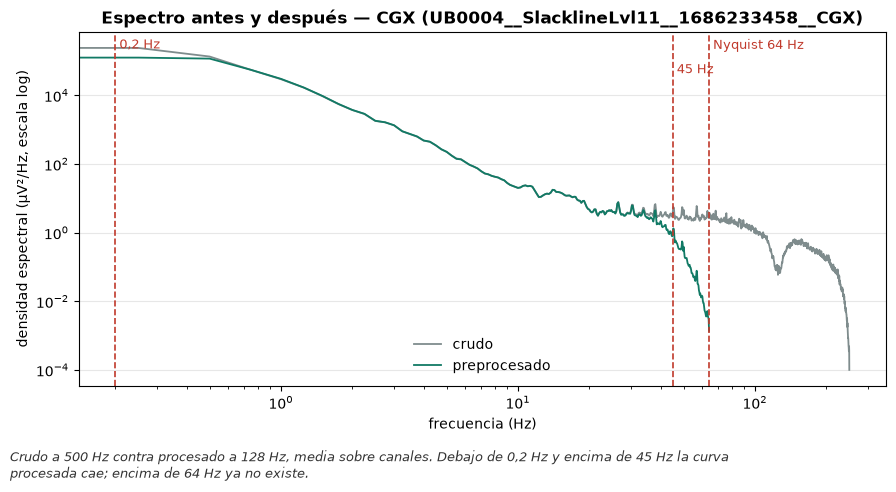

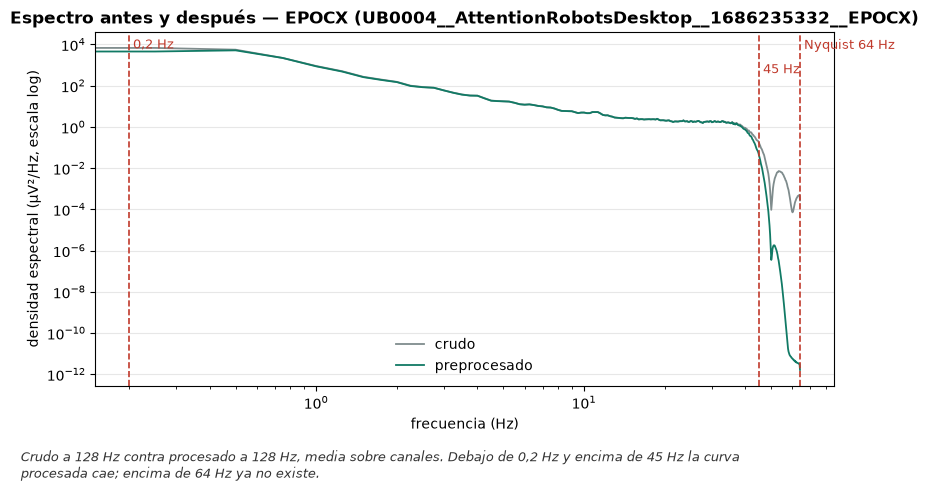

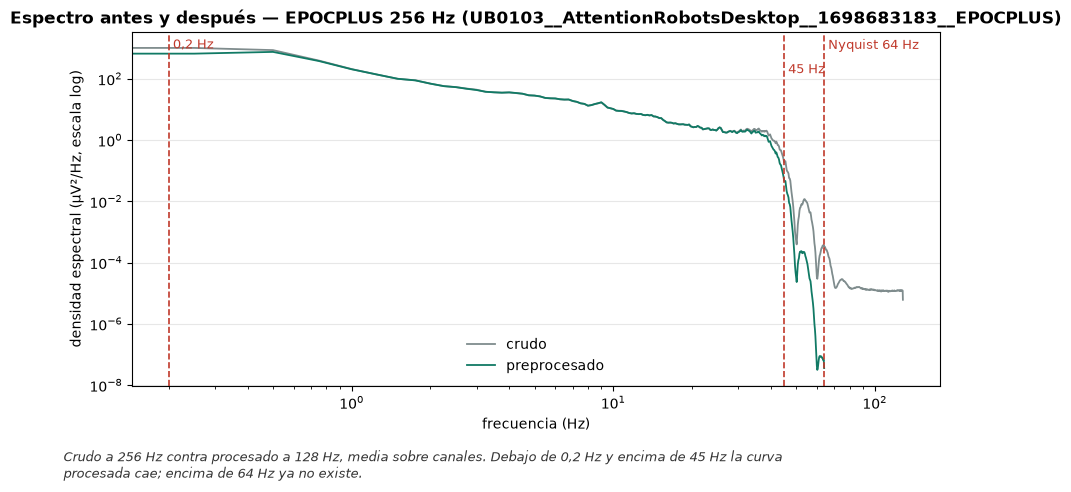

,ejemplo,tasa cruda,potencia 8–12 Hz (procesada/cruda),potencia 49–51 Hz,potencia 55–60 Hz
0,CGX,500.0,1.0019,0.0878,0.0112
1,EPOCX,128.0,1.0008,0.0069,0.0000
2,EPOCPLUS 256 Hz,256.0,1.0040,0.0699,0.0079


In [7]:
def psd_raw(record_id: str):
    row = inventory.eeg_records(inventory.build_index(RAW)).set_index("record_id").loc[record_id]
    record = modality.read_record(RAW / row["path"])
    scalp, _ = preprocess_filter.scalp_signal(record)
    rate = float(record.nominal_rate)
    f, p = welch(scalp - scalp.mean(axis=0), fs=rate, nperseg=int(rate * 4), axis=0)
    return f, p.mean(axis=1), rate

def psd_processed(npz: str):
    with np.load(OUT / npz) as z:
        x = np.concatenate(list(z["signal"]), axis=1)      # canales x muestras
    f, p = welch(x - x.mean(axis=1, keepdims=True), fs=128.0, nperseg=512, axis=1)
    return f, p.mean(axis=0)

def band_ratio(f_raw, p_raw, f_pro, p_pro, lo, hi):
    a = p_raw[(f_raw >= lo) & (f_raw <= hi)].mean()
    b = p_pro[(f_pro >= lo) & (f_pro <= hi)].mean()
    return b / a

# Per device, the record with the smallest fraction of integrity-marked windows.
kept = manifest[~manifest.excluded].assign(
    marked=lambda t: t.windows_integrity_marked.fillna(0) / t.n_windows)
pick = lambda rows: rows.sort_values(["marked", "record_id"]).iloc[0]
examples = {d: pick(kept[kept.device == d]) for d in ("CGX", "EPOCX")}
examples["EPOCPLUS 256 Hz"] = pick(kept[(kept.device == "EPOCPLUS") & (kept.nominal_rate == 256)])
ratios = []
for name, row in examples.items():
    f_raw, p_raw, rate = psd_raw(row["record_id"])
    f_pro, p_pro = psd_processed(row["npz"])
    fig = audit_plots.psd_before_after(
        (f_raw, p_raw), (f_pro, p_pro), f"Espectro antes y después — {name} ({row['record_id']})",
        f"Crudo a {rate:.0f} Hz contra procesado a 128 Hz, media sobre canales. Debajo de 0,2 Hz "
        "y encima de 45 Hz la curva procesada cae; encima de 64 Hz ya no existe.",
        lines={"0,2 Hz": 0.2, "45 Hz": 45.0, "Nyquist 64 Hz": 64.0})
    fig.axes[0].set_xscale("log")
    audit_plots.save(fig, f"03_2.7_psd_{name.split()[0]}", FIG); plt.show()
    ratios.append({"ejemplo": name, "tasa cruda": rate,
                   "potencia 8–12 Hz (procesada/cruda)": band_ratio(f_raw, p_raw, f_pro, p_pro, 8, 12),
                   "potencia 49–51 Hz": band_ratio(f_raw, p_raw, f_pro, p_pro, 49, 51),
                   "potencia 55–60 Hz": band_ratio(f_raw, p_raw, f_pro, p_pro, 55, 60)})
pd.DataFrame(ratios).round(4)

## 3.1 — Ventanas por registro

Ventanas de 4 s sin solape: 512 muestras a 128 Hz. Cada ventana procesada contiene exactamente las muestras de un bloque de muestras crudas de 4 s (2000 en CGX, 1024 en EPOC+ a 256 Hz, 512 a 128 Hz), la misma convención que usó la auditoría. Se descarta la primera ventana de cada registro (el transitorio del filtro, sección 2.7) y la parcial final (sección 3.1).

ventanas totales conservadas: 112351


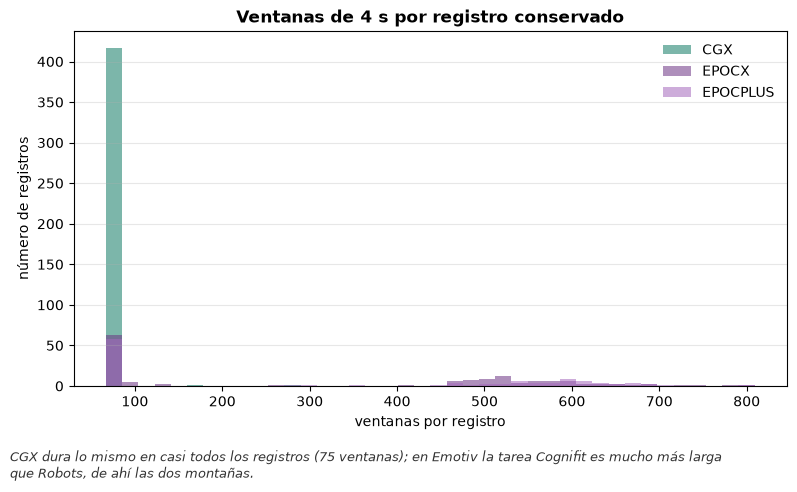

,count,min,50%,max,ventanas en total,descartadas (primera)
device,,,,,,
CGX,419.0,75.0,75.0,282.0,31787,419
EPOCPLUS,114.0,67.0,77.5,796.0,36112,114
EPOCX,141.0,68.0,263.0,809.0,44452,141


In [8]:
kept = manifest[~manifest.excluded]
table = kept.groupby("device")["n_windows"].describe()[["count", "min", "50%", "max"]]
table["ventanas en total"] = kept.groupby("device")["n_windows"].sum()
table["descartadas (primera)"] = kept.groupby("device").size()
print("ventanas totales conservadas:", int(kept["n_windows"].sum()))
fig = audit_plots.hist(None, "Ventanas de 4 s por registro conservado", "ventanas por registro",
    caption="CGX dura lo mismo en casi todos los registros (75 ventanas); en Emotiv la tarea "
    "Cognifit es mucho más larga que Robots, de ahí las dos montañas.",
    groups={d: kept.loc[kept.device == d, "n_windows"] for d in ("CGX", "EPOCX", "EPOCPLUS")},
    bins=40)
audit_plots.save(fig, "03_3.1_ventanas_por_registro", FIG); plt.show()
table

In [9]:
by_condition = kept.pivot_table(index="condition", values="n_windows",
                                aggfunc=["count", "median", "sum"])
by_condition.columns = ["registros", "mediana de ventanas", "ventanas"]
by_condition

,registros,mediana de ventanas,ventanas
condition,,,
Cognifit/EMOTIV,127,552.0,71124
Robots/EMOTIV,128,72.0,9440
Slackline-L1/CGX,140,75.0,10520
Slackline-L11/CGX,140,75.0,10823
Slackline-L6/CGX,139,75.0,10444


## 2.3, 2.4, 2.5 y 2.8 — Marcas por ventana

Las marcas son datos laterales y no tocan la señal (hay una prueba que lo fija). Cada una se calcula con la misma función que usó la auditoría, de modo que un registro marcado allí queda marcado igual aquí:

* **integridad** (2.3): alguna muestra perdida o interpolada en la ventana; un hueco más largo que una ventana marca las ventanas que toca;
* **plano / saturado** (2.4): por canal, varianza cero en la ventana o alguna muestra en el riel del dispositivo;
* **contacto** (2.5, solo Emotiv): por canal, mediana de `CQ` en la ventana por debajo del nivel 4;
* **ocular** (2.8): pico a pico frontal y razón 0,5–4 Hz frontal/posterior, como valores, sin corte.

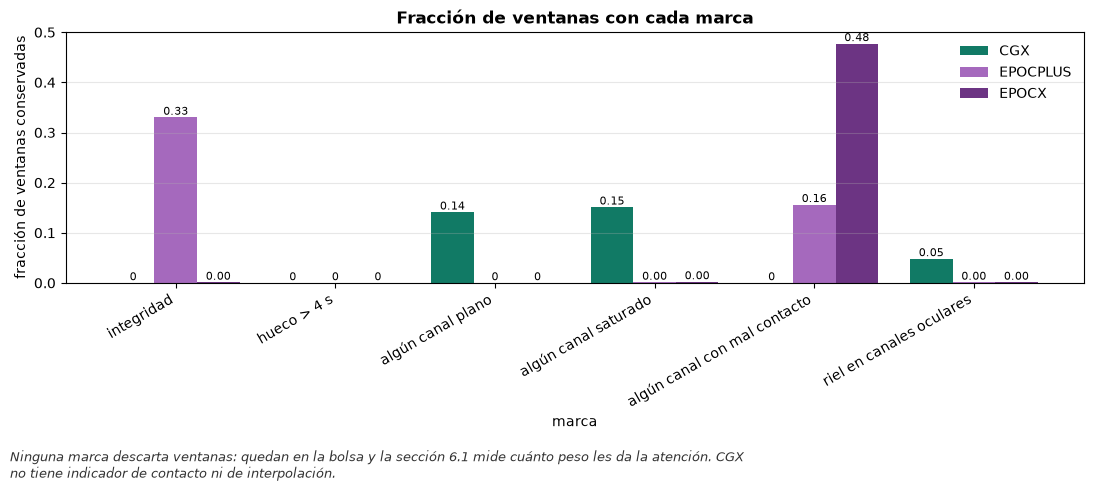

,n_windows,windows_integrity_marked,windows_long_gap,windows_any_flat,windows_any_saturated,windows_any_contact_bad,windows_rail_ocular
device,,,,,,,
CGX,31787,0.0,0.0,4477.0,4805.0,0.0,1540.0
EPOCPLUS,36112,11914.0,6.0,0.0,25.0,5648.0,21.0
EPOCX,44452,61.0,1.0,0.0,74.0,21221.0,65.0


In [10]:
marks = kept.groupby("device")[["n_windows", "windows_integrity_marked", "windows_long_gap",
                                "windows_any_flat", "windows_any_saturated",
                                "windows_any_contact_bad", "windows_rail_ocular"]].sum()
fractions = marks.drop(columns="n_windows").div(marks["n_windows"], axis=0)
fractions.columns = ["integridad", "hueco > 4 s", "algún canal plano", "algún canal saturado",
                     "algún canal con mal contacto", "riel en canales oculares"]
fig = audit_plots.grouped_bar(fractions.T.round(3), "Fracción de ventanas con cada marca",
    "marca", "fracción de ventanas conservadas",
    "Ninguna marca descarta ventanas: quedan en la bolsa y la sección 6.1 mide cuánto peso les da "
    "la atención. CGX no tiene indicador de contacto ni de interpolación.", figsize=(11, 4.5))
audit_plots.save(fig, "03_marcas_por_ventana", FIG); plt.show()
marks

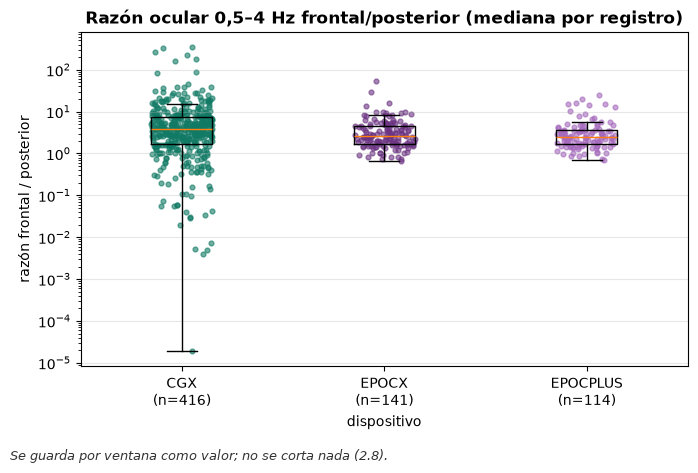

In [11]:
fig = audit_plots.box_by_group(
    {d: kept.loc[kept.device == d, "low_ratio_median"] for d in ("CGX", "EPOCX", "EPOCPLUS")},
    "Razón ocular 0,5–4 Hz frontal/posterior (mediana por registro)", "dispositivo",
    "razón frontal / posterior", "Se guarda por ventana como valor; no se corta nada (2.8).",
    log_y=True)
audit_plots.save(fig, "03_2.8_razon_ocular", FIG); plt.show()

## 2.2, 2.4, 2.5 y 2.10 — Exclusiones y tabla de flujo

Excluyen exactamente tres reglas, todas defectos duros del registro: la tasa (2.2), el registro sin EEG (2.4: más de la mitad de sus canales planos o saturados en todas sus ventanas) y la regla de contacto por mayoría (2.5). Un registro que cumple dos sale en la primera. Lo que el plan afirma de cada regla (qué registro deja sin EEG, cuántos registros, sujetos y modelos cumplen la regla de contacto) se comprueba con `assert` contra lo recién calculado desde el crudo.

Los sujetos con diagnóstico indeterminado **no** se excluyen aquí: quedan marcados en el manifiesto y los deja fuera la sección 4.3.

In [12]:
# Lo que el plan declara, comprobado contra lo que el pipeline acaba de calcular desde el crudo.
no_eeg = manifest[manifest.exclusion_reason.str.contains("2.4 no_eeg", regex=False)]
assert [(r.subject, r.task_label, r.device) for r in no_eeg.itertuples()] == [
    ("UB0058", "Slackline-L6", "CGX")], no_eeg.record_id.tolist()           # 2.4
contact = manifest[manifest.contact_meets_rule.fillna(False).astype(bool)]
assert len(contact) == 8 and contact.subject.nunique() == 8                  # 2.5: 8 de 263, 8 sujetos
assert contact.device.value_counts().to_dict() == {"EPOCX": 4, "EPOCPLUS": 4}  # cuatro de cada modelo
assert (manifest.family == "EMOTIV").sum() == 263
rate = manifest[manifest.exclusion_reason.str.contains("2.2 rate", regex=False)]
print("2.2 tasa:", rate.record_id.tolist())
manifest.loc[manifest.excluded, ["record_id", "device", "exclusion_step", "exclusion_reason",
                                 "label", "sex", "age"]].reset_index(drop=True)

2.2 tasa: ['UB0095__AttentionRobotsDesktop__1696608842__EPOCX']


,record_id,device,exclusion_step,exclusion_reason,label,sex,age
0,UB0058__AttentionRobotsDesktop__1686671395__EPOCX,EPOCX,2.5 contacto,2.5 majority_bad_contact,undetermined,M,7
1,UB0058__SlacklineLvl6__1686666919__CGX,CGX,2.4 registro sin EEG,2.4 no_eeg,undetermined,M,7
2,UB0095__AttentionRobotsDesktop__1696608842__EPOCX,EPOCX,2.2 tasa,2.2 rate_hard_defect;2.5 majority_bad_contact,yes,F,13
3,UB0097__Cognifit__1696525827__EPOCX,EPOCX,2.5 contacto,2.5 majority_bad_contact,yes,M,7
4,UB0098__AttentionRobotsDesktop__1696950715__EPOCX,EPOCX,2.5 contacto,2.5 majority_bad_contact,yes,M,6
5,UB0117__Cognifit__1701798881__EPOCPLUS,EPOCPLUS,2.5 contacto,2.5 majority_bad_contact,no,M,9
6,UB0137__AttentionRobotsDesktop__1706550171__EP...,EPOCPLUS,2.5 contacto,2.5 majority_bad_contact,yes,M,11
7,UB0153__Cognifit__1716370104__EPOCPLUS,EPOCPLUS,2.5 contacto,2.5 majority_bad_contact,yes,F,11
8,UB0172__Cognifit__1730116620__EPOCPLUS,EPOCPLUS,2.5 contacto,2.5 majority_bad_contact,yes,M,14


CGX


,step,records_meeting_rule,records_excluded,records_left,subjects_left,undetermined_subjects_flagged
0,inicial,0,0,420,145,18
1,lectura,0,0,420,145,18
2,2.2 tasa,0,0,420,145,18
3,2.4 registro sin EEG,1,1,419,145,18
4,2.5 contacto,0,0,419,145,18
5,final,0,1,419,145,18


EMOTIV


,step,records_meeting_rule,records_excluded,records_left,subjects_left,undetermined_subjects_flagged
0,inicial,0,0,263,142,19
1,lectura,0,0,263,142,19
2,2.2 tasa,1,1,262,141,19
3,2.4 registro sin EEG,0,0,262,141,19
4,2.5 contacto,8,7,255,138,18
5,final,0,8,255,138,18


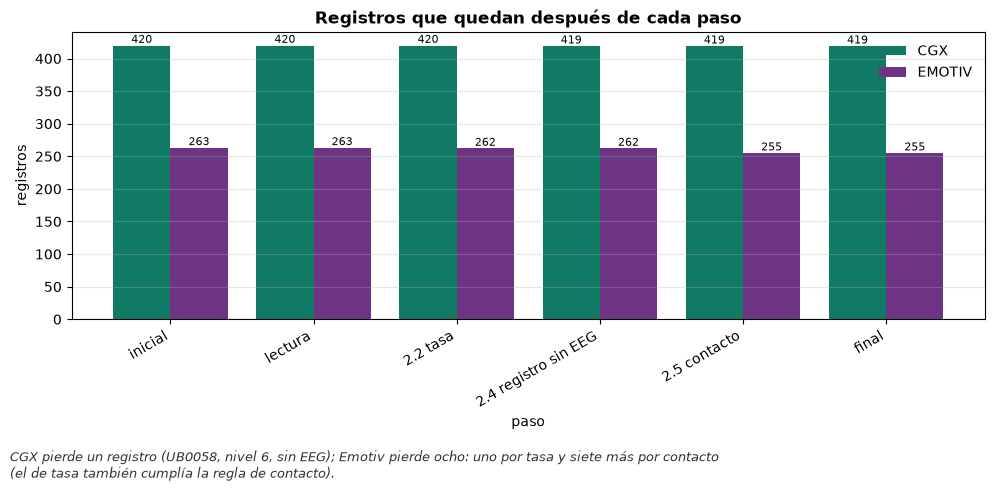

In [13]:
for family, flow in outputs["flows"].items():
    print(family)
    display(flow)
steps = outputs["flows"]["CGX"]["step"]
left = pd.DataFrame({f: outputs["flows"][f].set_index("step")["records_left"]
                     for f in ("CGX", "EMOTIV")}).loc[steps]
fig = audit_plots.grouped_bar(left, "Registros que quedan después de cada paso", "paso",
    "registros", "CGX pierde un registro (UB0058, nivel 6, sin EEG); Emotiv pierde ocho: uno por "
    "tasa y siete más por contacto (el de tasa también cumplía la regla de contacto).",
    figsize=(10, 4.5))
audit_plots.save(fig, "03_2.10_flujo_registros", FIG); plt.show()

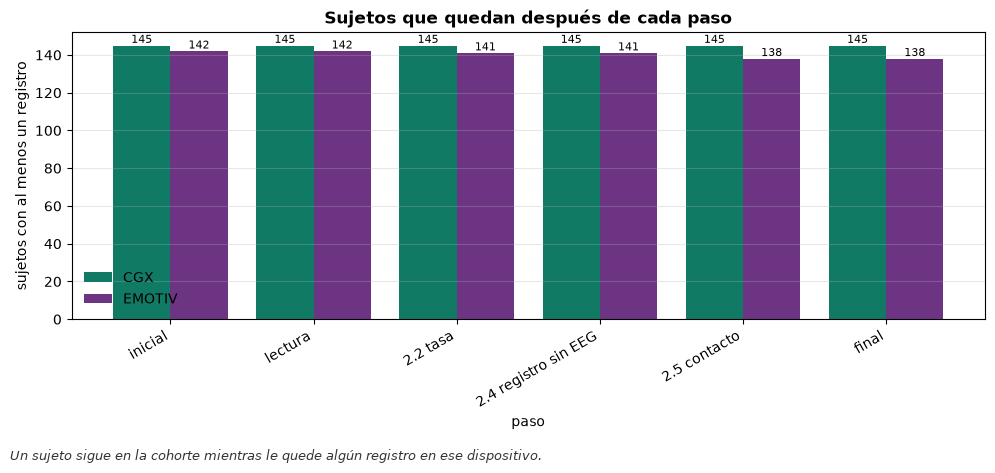

indeterminados marcados y conservados: 82 registros de 20 sujetos


In [14]:
subjects = pd.DataFrame({f: outputs["flows"][f].set_index("step")["subjects_left"]
                         for f in ("CGX", "EMOTIV")}).loc[steps]
fig = audit_plots.grouped_bar(subjects, "Sujetos que quedan después de cada paso", "paso",
    "sujetos con al menos un registro", "Un sujeto sigue en la cohorte mientras le quede algún "
    "registro en ese dispositivo.", figsize=(10, 4.5))
audit_plots.save(fig, "03_2.10_flujo_sujetos", FIG); plt.show()
undetermined = manifest[manifest.undetermined & ~manifest.excluded]
print("indeterminados marcados y conservados:", len(undetermined), "registros de",
      undetermined["subject"].nunique(), "sujetos")

## 2.10 — Las exclusiones cruzadas con etiqueta, sexo y edad

Defectos duros e incompatibilidades por separado, cada uno con su tabla. Aquí todas las exclusiones son defectos duros; la tabla de incompatibilidades se escribe y está vacía. Un sujeto cuenta como excluido en una cohorte cuando alguno de sus registros en ella salió.

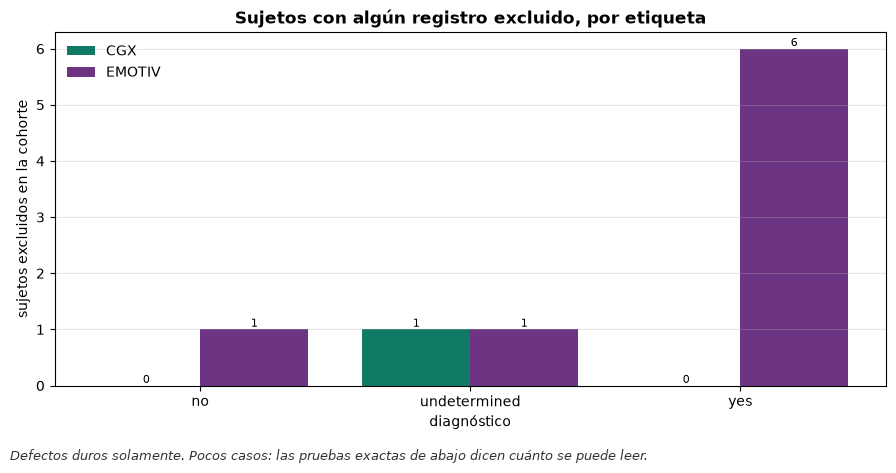

,family,value,total,median_age
5,CGX,excluded,1,7.0
6,CGX,kept,144,12.0
12,EMOTIV,excluded,8,10.0
13,EMOTIV,kept,134,12.0


,label_yes_vs_no_fisher_p,sex_fisher_p,age_mannwhitney_p
family,,,
CGX,1.000000,1.000000,0.133555
EMOTIV,0.419557,0.475425,0.039015


incompatibilidades excluidas: 0


In [15]:
crosses = outputs["crosses"]
hard = crosses[crosses.kind == "hard_defect"]
label = hard[hard.by == "label"].pivot_table(index="value", columns="family", values="excluded")
fig = audit_plots.grouped_bar(label, "Sujetos con algún registro excluido, por etiqueta",
    "diagnóstico", "sujetos excluidos en la cohorte",
    "Defectos duros solamente. Pocos casos: las pruebas exactas de abajo dicen cuánto se puede leer.")
audit_plots.save(fig, "03_2.10_exclusiones_por_etiqueta", FIG); plt.show()
tests = hard.groupby("family")[["label_yes_vs_no_fisher_p", "sex_fisher_p", "age_mannwhitney_p"]].first()
display(hard[hard.by == "age"][["family", "value", "total", "median_age"]])
display(tests)
print("incompatibilidades excluidas:",
      int(crosses.loc[crosses.kind == "incompatibility", "excluded"].fillna(0).sum()))

In [16]:
positive = {(f, t): p for f, row in tests.iterrows() for t, p in row.items() if p is not None and p < 0.05}
print("comprobaciones con p < 0.05:", positive or "ninguna")

comprobaciones con p < 0.05: {('EMOTIV', 'age_mannwhitney_p'): 0.039015323140379185}


## Lectura

* Las tres reglas seleccionan exactamente los registros que la auditoría y el plan nombran: UB0058 nivel 6 en CGX (sin EEG), UB0095 Robots EPOCX por tasa, y los ocho de la regla de contacto, uno de los cuales es ese mismo UB0095. En total salen 9 registros distintos de 683: 1 de 420 en CGX y 8 de 263 en Emotiv.
* **Una de las comprobaciones de la sección 2.10 resulta positiva y se declara**: en Emotiv los sujetos excluidos son más chicos que los conservados (mediana 10 contra 12 años, Mann-Whitney p ≈ 0,04, 8 sujetos excluidos). Con la etiqueta y con el sexo no hay asociación. La edad ya difiere entre los grupos diagnósticos y está entre las amenazas a la validez; esta exclusión la desplaza un poco más en la cohorte objetivo.
* El borde de 45 Hz es el de un Butterworth de fase cero, no una pared: en el ejemplo CGX la banda 49–51 Hz conserva cerca del 9 % de su potencia, y en el EPOC+ a 256 Hz cerca del 7 %; el EPOC X a 128 Hz ya venía filtrado por el dispositivo. La banda 8–12 Hz queda intacta.
* En EPOC+ un tercio de las ventanas lleva marca de integridad (casi todas por muestras interpoladas que declara el propio dispositivo); en EPOC X y CGX casi ninguna. UB0058 pierde sus dos registros, uno en cada dispositivo, y es indeterminado: la sección 4.3 ya lo dejaba fuera.
* Nada de esto toca la señal: las marcas son datos laterales y las ventanas marcadas siguen en la bolsa.

In [17]:
size = sum(p.stat().st_size for p in OUT.rglob("*") if p.is_file())
print(f"tamaño en disco de MIL-CREDA/Data/processed: {size / 1e9:.2f} GB")

tamaño en disco de MIL-CREDA/Data/processed: 4.21 GB
